In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from scipy.signal import correlate

merged = pd.read_csv("../data/processed/all_cities_combined.csv")
merged["week"] = pd.to_datetime(merged["week"])

CITIES = ["bangkok", "krakow", "melbourne"]
TERMS  = ["air_quality", "air_purifier", "N95_mask"]

print("Loaded ✓")
print(merged.groupby("city")[["pm25_mean","air_quality"]].describe().round(2))

Loaded ✓
          pm25_mean                                                  \
              count   mean   std    min    25%    50%    75%    max   
city                                                                  
bangkok       153.0  24.04  9.71  12.21  15.60  21.87  29.40  68.00   
krakow        143.0  17.95  9.49   4.85  11.00  15.65  22.01  49.68   
melbourne     101.0   5.81  2.15   3.09   4.47   5.49   6.56  15.50   

          air_quality                                              
                count   mean    std  min   25%   50%   75%    max  
city                                                               
bangkok         153.0  20.24  19.79  0.0   8.0  12.0  23.0  100.0  
krakow          143.0  18.73  15.27  0.0  11.0  16.0  22.5  100.0  
melbourne       101.0  10.80   3.07  6.0   9.0  10.0  13.0   23.0  


C:\conda_tmp\ipykernel_15640\2751592584.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_bin, labels=["Low\nPM2.5", "Medium\nPM2.5", "High\nPM2.5"],
C:\conda_tmp\ipykernel_15640\2751592584.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_bin, labels=["Low\nPM2.5", "Medium\nPM2.5", "High\nPM2.5"],
C:\conda_tmp\ipykernel_15640\2751592584.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_bin, labels=["Low\nPM2.5", "Medium\nPM2.5", "High\nPM2.5"],


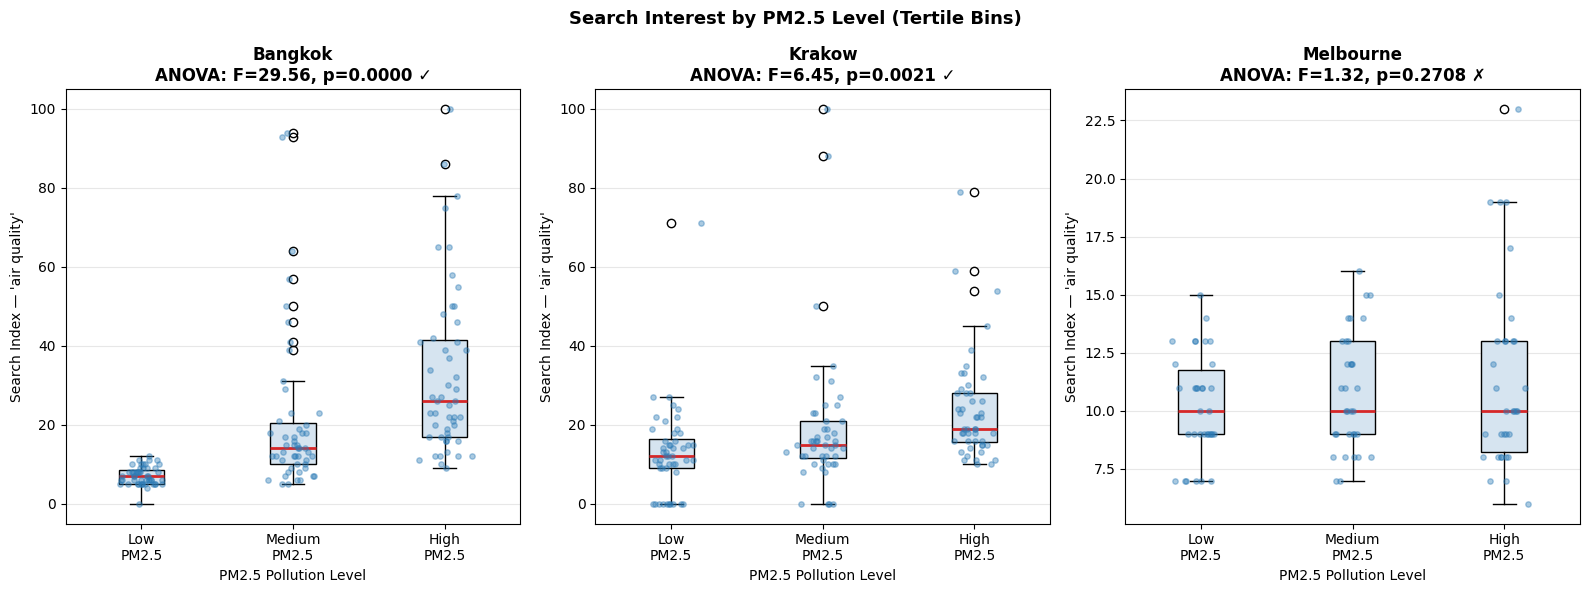

✓ Saved → outputs/figures/boxplot_bins.png


In [2]:
# Bin PM2.5 into Low / Medium / High per city using tertiles
def assign_bins(df):
    df = df.copy()
    df["pm25_bin"] = pd.qcut(df["pm25_mean"], q=3, 
                              labels=["Low", "Medium", "High"])
    return df

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, city in zip(axes, CITIES):
    df = merged[merged["city"] == city].copy().dropna()
    df = assign_bins(df)
    
    data_by_bin = [df[df["pm25_bin"]==b]["air_quality"].values 
                   for b in ["Low", "Medium", "High"]]
    
    bp = ax.boxplot(data_by_bin, labels=["Low\nPM2.5", "Medium\nPM2.5", "High\nPM2.5"],
                    patch_artist=True, notch=False,
                    boxprops=dict(facecolor="#d6e4f0"),
                    medianprops=dict(color="#d62728", linewidth=2))
    
    # Overlay individual points
    for i, d in enumerate(data_by_bin, 1):
        ax.scatter(np.random.normal(i, 0.07, len(d)), d, 
                   alpha=0.4, s=15, color="#2c7bb6", zorder=3)
    
    # ANOVA test
    f, p = stats.f_oneway(*data_by_bin)
    sig = f"p={p:.4f} ✓" if p < 0.05 else f"p={p:.4f} ✗"
    
    ax.set_title(f"{city.capitalize()}\nANOVA: F={f:.2f}, {sig}", 
                 fontweight="bold")
    ax.set_ylabel("Search Index — 'air quality'")
    ax.set_xlabel("PM2.5 Pollution Level")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Search Interest by PM2.5 Level (Tertile Bins)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/boxplot_bins.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → outputs/figures/boxplot_bins.png")

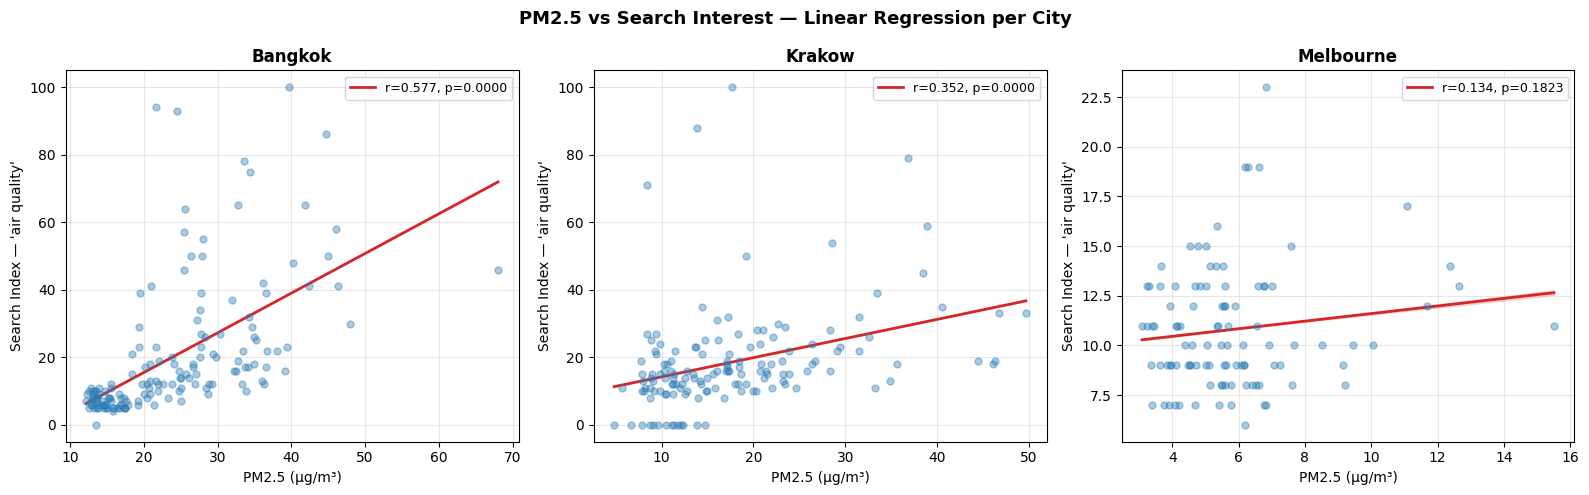

✓ Saved → outputs/figures/scatter_regression.png


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, city in zip(axes, CITIES):
    df = merged[merged["city"] == city].dropna()
    x = df["pm25_mean"]
    y = df["air_quality"]
    
    # Scatter
    ax.scatter(x, y, alpha=0.4, s=25, color="#2c7bb6", zorder=3)
    
    # Regression line
    slope, intercept, r, p, se = stats.linregress(x, y)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, slope * x_line + intercept, 
            color="#d62728", linewidth=2,
            label=f"r={r:.3f}, p={p:.4f}")
    
    # 95% confidence band
    n = len(x)
    x_mean = x.mean()
    se_band = se * np.sqrt(1/n + (x_line - x_mean)**2 / ((x - x_mean)**2).sum())
    t_crit = stats.t.ppf(0.975, df=n-2)
    y_pred = slope * x_line + intercept
    ax.fill_between(x_line, 
                    y_pred - t_crit * se_band,
                    y_pred + t_crit * se_band,
                    alpha=0.15, color="#d62728")
    
    ax.set_title(f"{city.capitalize()}", fontweight="bold")
    ax.set_xlabel("PM2.5 (µg/m³)")
    ax.set_ylabel("Search Index — 'air quality'")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle("PM2.5 vs Search Interest — Linear Regression per City",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/scatter_regression.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → outputs/figures/scatter_regression.png")

In [4]:
print("=" * 65)
print(f"{'FINAL RESULTS SUMMARY':^65}")
print("=" * 65)

rows = []
for city in CITIES:
    df = merged[merged["city"] == city].dropna()
    for term in TERMS:
        if df[term].std() == 0:
            continue
        r, p = stats.pearsonr(df["pm25_mean"], df[term])
        pm25_norm = (df["pm25_mean"] - df["pm25_mean"].mean()) / df["pm25_mean"].std()
        srch_norm = (df[term] - df[term].mean()) / df[term].std()
        cc = correlate(srch_norm, pm25_norm, mode="full")
        lags = np.arange(-(len(pm25_norm)-1), len(pm25_norm))
        mask = (lags >= -8) & (lags <= 8)
        peak_lag = lags[mask][np.argmax(cc[mask])]
        rows.append({
            "City": city.capitalize(),
            "Term": term,
            "Pearson r": round(r, 3),
            "p-value": round(p, 4),
            "Significant": "✓" if p < 0.05 else "✗",
            "Peak Lag (weeks)": int(peak_lag)
        })

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
summary.to_csv("../data/processed/results_summary.csv", index=False)
print("\n✓ Saved → data/processed/results_summary.csv")

                      FINAL RESULTS SUMMARY                      
     City         Term  Pearson r  p-value Significant  Peak Lag (weeks)
  Bangkok  air_quality      0.577   0.0000           ✓                -1
  Bangkok air_purifier      0.522   0.0000           ✓                -1
  Bangkok     N95_mask      0.233   0.0038           ✓                -1
   Krakow  air_quality      0.352   0.0000           ✓                -1
   Krakow air_purifier      0.500   0.0000           ✓                -1
Melbourne  air_quality      0.134   0.1823           ✗                -1
Melbourne air_purifier     -0.119   0.2379           ✗                -7
Melbourne     N95_mask     -0.001   0.9928           ✗                -8

✓ Saved → data/processed/results_summary.csv
